# Eksperimen Pribadi — Tugas 3 Bagian B.v: Agregasi Fitur dengan Sliding Window Temporal

> "Teknik agregasi fitur melalui sliding window temporal (contoh: rata-rata vektor harian, bobot peluruhan eksponensial untuk dampak berita, atau attention pada alur judul berita)."

**Masalah yang dijawab:** sampai sekarang, fitur hari *t* hanya dari berita hari *t* (rata-rata vektor artikel hari itu). Padahal dampak berita bisa **bertahan beberapa hari**, dan hari tanpa berita diisi vektor netral. Apakah **mengingat berita beberapa hari ke belakang** membantu?

**Teknik yang dibandingkan** (semua *kausal*: hari *t* hanya memakai berita dengan tanggal ≤ *t*):

| Kode | Teknik | Bobot artikel berumur `a` hari |
|---|---|---|
| W=1 | rata-rata harian (acuan, sama dengan B.iv) | 1 jika a = 0 |
| W=3, W=7 | **sliding window** rata-rata | 1 jika a < W, selain itu 0 |
| h=1, 3, 7 | **peluruhan eksponensial** (half-life h hari) | 2^(−a/h) |
| Attn | **attention** atas judul 5 hari terakhir (jaringan kecil, dilatih di train) | dipelajari |
| Seragam | pembanding Attn tanpa attention (rata-rata seragam) | 1/jumlah judul |

Peluruhan eksponensial juga menjawab masalah **hari tanpa berita**: vektor hari itu diisi dari sisa berita sebelumnya, bukan netral.

**Embedding:** FinBERT dan MiniLM (dipilih sejak awal; PCA k=10 tetap). Tidak ada penyetelan terhadap val/test; half-life dan ukuran window ditetapkan di muka.

**Prasyarat:** cache embedding artikel dari B (FinBERT, MiniLM) dan embedding **judul** dari B.i (`title_FinBERT_ml64.npz` / `title_MiniLM_ml64.npz`) untuk bagian Attn; set yang cache-nya tidak ada dilewati.

## 0. Setup

In [1]:
import sys, re, json, time, pickle, warnings
sys.dont_write_bytecode = True
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.decomposition import PCA
import torch, torch.nn as nn
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef
warnings.filterwarnings("ignore")

def find_root():
    '''Cari root repo dari folder notebook (jalan dari notebook/ maupun src/notebook/).'''
    here = Path.cwd().resolve()
    for q in (here, *here.parents):
        if (q / "data" / "export" / "articles.parquet").exists() and (q / "src" / "eval_utils.py").exists():
            return q
    raise FileNotFoundError("root repo (data/export + src/eval_utils.py) tidak ditemukan dari " + str(here))

ROOT = find_root()
sys.path.append(str(ROOT / "src"))
from eval_utils import evaluate, naive_baselines

EXPORT_DIR = ROOT / "data" / "export"
CACHE_DIR = Path("cache_embeddings"); CACHE_DIR.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
print("root repo:", ROOT)

root repo: /Users/farsyaant/nlpproject-baru


## 1. Muat data dan split

In [2]:
articles = pd.read_parquet(EXPORT_DIR / "articles.parquet").sort_values("article_id").reset_index(drop=True)
prices   = pd.read_parquet(EXPORT_DIR / "prices_daily.parquet")
sent     = pd.read_parquet(EXPORT_DIR / "sentiment_daily.parquet")
splits   = json.loads((EXPORT_DIR / "splits.json").read_text())

KURS_COLS = ["kurs_lag1", "kurs_lag2", "kurs_lag3", "kurs_lag4", "kurs_lag5", "kurs_roll_mean5", "kurs_roll_std5"]
LEX_COLS = [c for c in sent.columns if c not in ("date", "news_count")]
assert len(KURS_COLS) == 7 and len(LEX_COLS) == 16

daily = (prices.merge(sent[["date", "news_count"] + LEX_COLS], on="date", how="left")
               .sort_values("date").reset_index(drop=True))
assert daily[LEX_COLS].notna().all().all()
for s in ("train", "val", "test"):
    assert (daily["split"] == s).sum() == splits[s]["n"]
tr = (daily["split"] == "train").to_numpy(); va = (daily["split"] == "val").to_numpy(); te = (daily["split"] == "test").to_numpy()
y = daily["target"].to_numpy()

articles["split"] = articles["aligned_trading_date"].map(dict(zip(daily["date"], daily["split"])))
articles["text_raw"] = articles["title"].fillna("").str.strip() + ". " + articles["full_text"].fillna("").str.strip()
print("baris per split:", tr.sum(), va.sum(), te.sum())
print(articles["split"].value_counts(dropna=False).to_string())

baris per split: 836 178 180
split
train    2489
test     1220
val       619
NaN         4


## 2. Muat embedding dari cache

In [3]:
FILES = {"FinBERT": "FinBERT_cw300_mc2_ml512.npz", "MiniLM": "MiniLM_cw160_mc5_ml256.npz"}
TITLE_FILES = {"FinBERT": "title_FinBERT_ml64.npz", "MiniLM": "title_MiniLM_ml64.npz"}
EMB, FBP = {}, None
for tag, fn in FILES.items():
    f = CACHE_DIR / fn
    if not f.exists(): print(f"LEWATI {tag}: {fn} belum ada"); continue
    z = np.load(f, allow_pickle=True); assert len(z["A"]) == len(articles); EMB[tag] = z["A"].astype(np.float64)
    if tag == "FinBERT": FBP = (z["P"], z["labels"].item())
    print(tag, EMB[tag].shape)

# indeks hari tiap artikel (artikel di luar kalender trading dibuang)
date_idx = {d: i for i, d in enumerate(daily["date"])}
art_day = articles["aligned_trading_date"].map(date_idx)
keep = art_day.notna().to_numpy(); art_day_i = art_day.fillna(-1).astype(int).to_numpy()
dates = pd.to_datetime(daily["date"]).to_numpy()
T = len(daily)
AGE = (dates[:, None] - dates[None, :]).astype("timedelta64[D]").astype(int)   # AGE[t, d] = umur (hari kalender) berita hari d terhadap hari t
print("hari:", T, "| artikel dipakai:", int(keep.sum()), "| umur maksimum dalam matriks:", AGE.max())

FinBERT (4332, 768)
MiniLM (4332, 384)
hari: 1194 | artikel dipakai: 4328 | umur maksimum dalam matriks: 1818


## 3. Diagnostik: seberapa lama berita "bertahan"?

Sebelum memilih window, lihat **korelasi lag**: seberapa kuat fitur teks pada hari *t−L* berhubungan dengan target hari *t* (Spearman, hanya hari train). Fitur: tiga komponen PCA pertama dari rata-rata harian dan sentimen net FinBERT (jika ada). Ambang p<0,05 tanpa koreksi: |ρ| ≈ 0,07 (n≈830). Kalau korelasi pada lag 1-5 tidak lebih kecil dari lag 0, ada "memori"; kalau semuanya nol, agregasi temporal tidak punya dasar.

In [4]:
def daily_sum(A):
    D = np.zeros((T, A.shape[1])); c = np.zeros(T)
    np.add.at(D, art_day_i[keep], A[keep]); np.add.at(c, art_day_i[keep], 1)
    return D, c

_, c_all = daily_sum(np.zeros((len(articles), 1))); HT = c_all > 0       # hari yang punya berita

def lag_table(series_dict, lags=range(0, 9)):
    out = {}
    for name, s in series_dict.items():
        row = []
        for L in lags:
            x = s[:T - L]; yy = y[L:]; m = tr[L:] & HT[:T - L]
            row.append(spearmanr(x[m], yy[m])[0])
        out[name] = row
    return pd.DataFrame(out, index=[f"lag {L}" for L in lags]).T.round(3)

series = {}
for tag in EMB:
    D, c = daily_sum(EMB[tag])
    M = np.where(HT[:, None], D / np.clip(c, 1, None)[:, None], 0.0)
    Z = PCA(n_components=3, random_state=SEED).fit(M[tr & HT]).transform(M)
    for j in range(3): series[f"{tag} PC{j + 1}"] = Z[:, j]
if FBP is not None:
    lab = {v: k for k, v in FBP[1].items()}; net = FBP[0][:, lab["positive"]] - FBP[0][:, lab["negative"]]
    D, c = daily_sum(net[:, None]); series["FinBERT net"] = np.where(HT, D[:, 0] / np.clip(c, 1, None), 0.0)
lag_table(series)

,lag 0,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,lag 7,lag 8
FinBERT PC1,0.039,-0.042,-0.038,0.032,-0.014,-0.047,0.006,-0.060,-0.029
FinBERT PC2,0.053,0.008,-0.029,0.001,-0.016,-0.011,-0.026,0.028,-0.059
FinBERT PC3,0.030,-0.014,0.062,-0.010,-0.033,0.008,-0.034,-0.026,-0.013
MiniLM PC1,0.013,0.017,0.031,-0.022,-0.005,0.042,-0.038,0.086,0.003
MiniLM PC2,0.070,0.017,-0.007,0.013,0.014,-0.020,-0.013,-0.020,0.021
MiniLM PC3,-0.057,0.034,-0.062,-0.023,-0.035,0.024,-0.023,0.002,0.028
FinBERT net,-0.056,0.035,0.070,-0.026,-0.012,0.023,0.044,-0.032,0.041


## 4. Fungsi agregasi

Untuk tiap hari *t*, vektor = **rata-rata berbobot** semua artikel dengan tanggal ≤ *t*:
`v_t = Σ w(umur) · (jumlah vektor hari d) / Σ w(umur) · (jumlah artikel hari d)`.
Jika total bobot 0 (tidak ada berita dalam jangkauan), hari itu diberi vektor netral (0 di ruang PCA). **PCA k=10 di-fit hanya pada hari train.**

**Cek kewarasan:** konfigurasi W=1 harus identik dengan rata-rata harian di B.iv (FinBERT k=10 dan MiniLM k=10 harus memberi angka sama dengan B.iv).

In [5]:
K_PCA = 10
CONFIGS = {"W=1 (hari ini)": ("win", 1), "W=3": ("win", 3), "W=7": ("win", 7),
           "h=1": ("exp", 1), "h=3": ("exp", 3), "h=7": ("exp", 7)}

def weights(kind, p):
    a = AGE.astype(float); valid = a >= 0                       # hanya masa lalu/hari yang sama (kausal)
    if kind == "win": w = ((a < p) & valid).astype(float)
    else: w = np.where(valid & (a <= 10 * p), 2.0 ** (-a / p), 0.0)   # potong di 10 half-life
    return w

def aggregate(A, kind, p):
    D, c = daily_sum(A); w = weights(kind, p)
    num, den = w @ D, w @ c
    has = den > 1e-12
    M = np.zeros_like(num); M[has] = num[has] / den[has][:, None]
    return M, has

def agg_features(A, kind, p, k=K_PCA):
    M, has = aggregate(A, kind, p)
    pca = PCA(n_components=20, random_state=SEED).fit(M[tr & has])        # 20 komponen lalu ambil k pertama, sama seperti B.iv
    Z = np.zeros((T, k)); Z[has] = pca.transform(M[has])[:, :k]
    return Z, int(has.sum())

FEATS, INFO = {}, []
for tag in EMB:
    for cname, (kind, p) in CONFIGS.items():
        Z, nd = agg_features(EMB[tag], kind, p)
        FEATS[f"C  {tag} {cname}"] = Z; INFO.append(dict(embedding=tag, konfigurasi=cname, hari_berfitur=nd, dari=T))
pd.DataFrame(INFO).pivot(index="konfigurasi", columns="embedding", values="hari_berfitur")

embedding,FinBERT,MiniLM
konfigurasi,,
W=1 (hari ini),1073,1073
W=3,1186,1186
W=7,1194,1194
h=1,1194,1194
h=3,1194,1194
h=7,1194,1194


Tabel di atas = **jumlah hari yang punya vektor nyata** (bukan netral). W=1 sama dengan jumlah hari yang punya berita; window/peluruhan menaikkannya karena hari tanpa berita tertutup oleh berita sebelumnya.

## 5. Attention atas alur judul

Tiap hari *t* diberi barisan judul 5 hari terakhir (maks 24 judul terbaru, urut waktu terbit). Tiap judul = embedding judul (PCA 16 komponen, fit hanya pada judul train) + umur relatifnya. Jaringan kecil:

1. skor tiap judul `s_i = v · tanh(W [x_i; umur_i])`, lalu `softmax` antar judul (hanya judul yang ada),
2. vektor hari = jumlah berbobot attention dari judul,
3. prediksi = regresi linear kurs + regresi linear vektor hari (dropout 0,3).

**Pembanding "Seragam":** jaringan yang sama, tetapi bobot **sama rata** untuk semua judul, sehingga selisihnya murni berasal dari attention. Pelatihan hanya pada train; **early stopping memakai 15% hari terakhir dari train** (bukan val); 5 seed dirata-rata. Ini model kecil pada ±700 sampel, jadi hasilnya sangat mungkin sama dengan baseline.

In [6]:
TITLE_TAG = next((t for t in ("FinBERT", "MiniLM") if (CACHE_DIR / TITLE_FILES[t]).exists()), None)
W_ATT, MAXI, P_ATT = 5, 24, 16
if TITLE_TAG is None:
    print("embedding judul belum ada (title_*_ml64.npz dari B.i) -> bagian Attn dilewati")
else:
    zt = np.load(CACHE_DIR / TITLE_FILES[TITLE_TAG], allow_pickle=True); TA = zt["A"].astype(np.float64); assert len(TA) == len(articles)
    art_tr = (articles["split"] == "train").to_numpy()
    pca_t = PCA(n_components=P_ATT, random_state=SEED).fit(TA[art_tr]); X_art = pca_t.transform(TA)
    X_art = X_art / X_art[art_tr].std(0)
    order = np.lexsort((articles["published_wib"].to_numpy(), art_day_i)); order = order[keep[order]]
    d_sorted = art_day_i[order]
    Xs = np.zeros((T, MAXI, P_ATT), np.float32); Ags = np.zeros((T, MAXI), np.float32); Ms = np.zeros((T, MAXI), bool)
    for t in range(T):
        lo = np.searchsorted(d_sorted, max(0, t - W_ATT + 1), "left"); hi = np.searchsorted(d_sorted, t, "right")
        idx = order[lo:hi][-MAXI:]
        # batas jendela berdasarkan hari kalender
        idx = np.array([i for i in idx if 0 <= AGE[t, art_day_i[i]] < W_ATT], dtype=int)
        n = len(idx)
        if n:
            Xs[t, :n] = X_art[idx]; Ags[t, :n] = AGE[t, art_day_i[idx]] / W_ATT; Ms[t, :n] = True
    print(f"judul: embedding {TITLE_TAG} | rata-rata judul per hari dalam window: {Ms.sum(1).mean():.1f} | hari tanpa judul: {(Ms.sum(1) == 0).sum()}")

judul: embedding FinBERT | rata-rata judul per hari dalam window: 11.5 | hari tanpa judul: 0


In [7]:
class AttnNet(nn.Module):
    def __init__(s, p, nk, h=16, attn=True, drop=0.3):
        super().__init__()
        s.W = nn.Linear(p + 1, h); s.v = nn.Linear(h, 1, bias=False)
        s.head = nn.Linear(p, 1); s.lin = nn.Linear(nk, 1); s.drop = nn.Dropout(drop); s.attn = attn
    def forward(s, X, age, mask, K):
        if s.attn:
            sc = s.v(torch.tanh(s.W(torch.cat([X, age.unsqueeze(-1)], -1)))).squeeze(-1)
        else:
            sc = torch.zeros_like(age)
        sc = sc.masked_fill(~mask, -1e9)
        a = torch.softmax(sc, 1) * mask                       # baris tanpa judul -> bobot 0 -> vektor 0
        pooled = (a.unsqueeze(-1) * X).sum(1)
        return s.lin(K).squeeze(-1) + s.head(s.drop(pooled)).squeeze(-1)

def train_attn(attn, seed, epochs=60, patience=10, lr=3e-3, wd=1e-2):
    torch.manual_seed(seed); np.random.seed(seed)
    Kz = StandardScaler().fit(KURS[tr]).transform(KURS).astype(np.float32)
    ym, ys = y[tr].mean(), y[tr].std(); yt = ((y - ym) / ys).astype(np.float32)
    X, Ag, Mk, Kt, Y = map(torch.tensor, (Xs, Ags, Ms, Kz, yt))
    idx_tr = np.where(tr)[0]; cut = int(len(idx_tr) * 0.85); fit_i, es_i = idx_tr[:cut], idx_tr[cut:]
    net = AttnNet(P_ATT, Kz.shape[1], attn=attn); opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    best, best_state, bad = 1e9, None, 0
    for ep in range(epochs):
        net.train(); perm = np.random.permutation(fit_i)
        for b in range(0, len(perm), 64):
            j = torch.tensor(perm[b:b + 64]); opt.zero_grad()
            loss = ((net(X[j], Ag[j], Mk[j], Kt[j]) - Y[j]) ** 2).mean(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): ve = float(((net(X[es_i], Ag[es_i], Mk[es_i], Kt[es_i]) - Y[es_i]) ** 2).mean())
        if ve < best - 1e-5: best, bad, best_state = ve, 0, {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    net.load_state_dict(best_state); net.eval()
    with torch.no_grad(): pred = net(X, Ag, Mk, Kt).numpy() * ys + ym
    return pred, ep + 1

ATTN_PRED = {}
if TITLE_TAG is not None:
    KURS = daily[KURS_COLS].to_numpy()
    for name, flag in (("Attn (W=5 hari)", True), ("Seragam (W=5 hari)", False)):
        ps, eps = zip(*[train_attn(flag, s) for s in range(5)])
        ATTN_PRED[name] = np.mean(ps, axis=0); print(f"{name}: epoch rata-rata {np.mean(eps):.0f}")

Attn (W=5 hari): epoch rata-rata 20
Seragam (W=5 hari): epoch rata-rata 23


## 6. Protokol evaluasi (identik dengan notebook sebelumnya)

In [8]:
MODELS = {
    "Ridge": lambda s: Ridge(alpha=10.0),
    "RandForest": lambda s: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=s),
    "GradBoost": lambda s: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=s),
}
SEEDS = (0, 1, 2)

def direction_metrics(y_true, y_pred):
    m = y_true != 0
    t, p = y_true[m] > 0, y_pred[m] > 0
    return {"BalAcc": balanced_accuracy_score(t, p), "MCC": matthews_corrcoef(t, p)}

def fit_predict(X):
    Xs = StandardScaler().fit(X[tr]).transform(X)
    preds = {}
    for name, make in MODELS.items():
        seeds = (0,) if name == "Ridge" else SEEDS
        preds[name] = np.mean([make(s).fit(Xs[tr], y[tr]).predict(Xs) for s in seeds], axis=0)
    return preds

rows = []
def run(set_name, X):
    for mname, p in fit_predict(X).items():
        for sp, mask in (("val", va), ("test", te)):
            r = evaluate(y[mask], p[mask]); r.update(direction_metrics(y[mask], p[mask]))
            rows.append(dict(set=set_name, model=mname, split=sp, **r))

ret_today = daily["ret"].to_numpy(); base_rows = []
for sp, mask in (("val", va), ("test", te)):
    nb = naive_baselines(y[mask], ret_today[mask])
    nb["Konstan (mean train)"] = evaluate(y[mask], np.full(mask.sum(), y[tr].mean()))
    preds = {"Prediksi 0": np.zeros(mask.sum()), "Return kemarin": ret_today[mask],
             "Konstan (mean train)": np.full(mask.sum(), y[tr].mean())}
    for name, r in nb.items():
        r = dict(r); r.update(direction_metrics(y[mask], preds[name]))
        base_rows.append(dict(set=name, model="-", split=sp, **r))

In [9]:
KURS = daily[KURS_COLS].to_numpy(); LEX = daily[LEX_COLS].to_numpy()
run("A  kurs", KURS); run("B  kurs+lexicon", np.hstack([KURS, LEX]))
for name, Z in FEATS.items(): run(name, np.hstack([KURS, Z]))
res = pd.DataFrame(rows); base = pd.DataFrame(base_rows)
print("selesai:", res["set"].nunique(), "set x", res["model"].nunique(), "model")

selesai: 14 set x 3 model


## 7. Hasil

### 7.1 Pembanding tanpa model

In [10]:
cols = ["MAE", "RMSE", "DirAcc", "BalAcc", "MCC"]
base.pivot(index="set", columns="split", values=cols).round(5)

MAE              RMSE            DirAcc          BalAcc               MCC         
split                    test      val     test      val     test      val   test      val     test      val
set                                                                                                         
Konstan (mean train)  0.00218  0.00246  0.00289  0.00338  0.59091  0.53409  0.500  0.50000  0.00000  0.00000
Prediksi 0            0.00221  0.00247  0.00291  0.00338  0.00000  0.00000  0.500  0.50000  0.00000  0.00000
Return kemarin        0.00308  0.00347  0.00398  0.00461  0.54545  0.50568  0.539  0.50908  0.07754  0.01816

### 7.2 Rata-rata 3 model per set fitur
`dRMSE%` terhadap A (negatif = lebih baik).

In [11]:
mean_tbl = res.groupby(["set", "split"])[["RMSE", "DirAcc", "BalAcc", "MCC"]].mean().unstack("split")
a_rmse = mean_tbl.loc["A  kurs", "RMSE"]
for sp in ("val", "test"):
    mean_tbl[("dRMSE%", sp)] = (mean_tbl[("RMSE", sp)] / a_rmse[sp] - 1) * 100
mean_tbl = mean_tbl.sort_values(("RMSE", "val"))
mean_tbl.round(5)

RMSE            DirAcc            BalAcc               MCC            dRMSE%         
split                         test      val     test      val     test      val     test      val      val     test
set                                                                                                                
C  FinBERT W=7             0.00295  0.00340  0.48864  0.50000  0.54095  0.51738  0.09894  0.03923 -0.94652 -2.59013
C  FinBERT W=1 (hari ini)  0.00295  0.00341  0.48295  0.50758  0.52475  0.52681  0.04366  0.06447 -0.77822 -2.60402
C  MiniLM h=7              0.00301  0.00341  0.44886  0.50189  0.50089  0.51111 -0.02012  0.02338 -0.76923 -0.63606
C  FinBERT h=3             0.00302  0.00341  0.44318  0.52273  0.48469  0.53840 -0.05689  0.08841 -0.73713 -0.20057
C  MiniLM h=3              0.00304  0.00341  0.42803  0.49242  0.49252  0.51003 -0.02077  0.01522 -0.55382  0.56323
C  MiniLM h=1              0.00299  0.00341  0.47159  0.50189  0.52368  0.52253  0.05788  0.05900 -0.55116 -1.37024
C  MiniLM W=7              0.00303  0.00342  0.42424  0.51705  0.50427  0.53879  0.01206  0.09543 -0.35087  0.05303
C  MiniLM W=1 (hari ini)   0.00300  0.00343  0.45644  0.50758  0.51371  0.52474  0.01940  0.05904 -0.16511 -0.86932
A  kurs                    0.00303  0.00343  0.40720  0.47159  0.49769  0.49728 -0.03028 -0.01454  0.00000  0.00000
C  MiniLM W=3              0.00304  0.00344  0.42235  0.50379  0.49769  0.52846 -0.01045  0.08267  0.22366  0.35052
C  FinBERT W=3             0.00300  0.00345  0.45265  0.46212  0.52618  0.48815  0.08522 -0.06031  0.37192 -0.79783
B  kurs+lexicon            0.00301  0.00346  0.44318  0.45644  0.49181  0.47557 -0.02755 -0.04702  0.62909 -0.47218
C  FinBERT h=1             0.00301  0.00346  0.48674  0.48295  0.54790  0.50350  0.10593  0.00744  0.70967 -0.57802
C  FinBERT h=7             0.00299  0.00347  0.47159  0.48674  0.51229  0.51198  0.03424  0.03646  0.93595 -1.24948

### 7.3 Per model (RMSE val)

In [12]:
pm = res[res["split"] == "val"].pivot(index="set", columns="model", values="RMSE")
pm["rata2"] = pm.mean(axis=1); pm.sort_values("rata2").round(6)

model,GradBoost,RandForest,Ridge,rata2
set,,,,
C FinBERT W=7,0.003396,0.003419,0.003389,0.003401
C FinBERT W=1 (hari ini),0.003399,0.003433,0.003390,0.003407
C MiniLM h=7,0.003362,0.003476,0.003385,0.003408
C FinBERT h=3,0.003390,0.003443,0.003392,0.003409
C MiniLM h=3,0.003389,0.003493,0.003363,0.003415
C MiniLM h=1,0.003393,0.003469,0.003384,0.003415
C MiniLM W=7,0.003402,0.003505,0.003358,0.003422
C MiniLM W=1 (hari ini),0.003425,0.003472,0.003388,0.003428
A kurs,0.003421,0.003493,0.003388,0.003434


### 7.4 Grafik

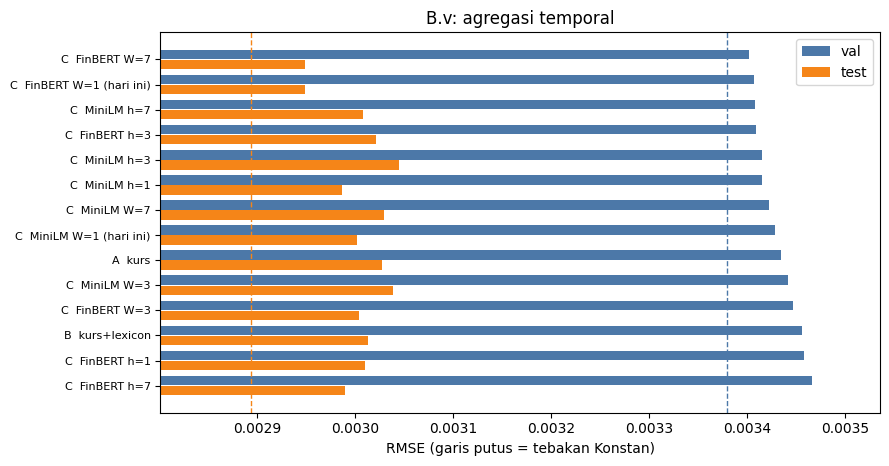

In [13]:
plot_df = mean_tbl["RMSE"].sort_values("val", ascending=False)
const = base[base["set"] == "Konstan (mean train)"].set_index("split")["RMSE"]
fig, ax = plt.subplots(figsize=(9, max(4, 0.34 * len(plot_df))))
yy = np.arange(len(plot_df))
ax.barh(yy + 0.2, plot_df["val"], height=0.38, label="val", color="#4C78A8")
ax.barh(yy - 0.2, plot_df["test"], height=0.38, label="test", color="#F58518")
ax.axvline(const["val"], color="#4C78A8", ls="--", lw=1); ax.axvline(const["test"], color="#F58518", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(plot_df.index, fontsize=8)
ax.set_xlim(plot_df.min().min() * 0.95, plot_df.max().max() * 1.02)
ax.set_xlabel("RMSE (garis putus = tebakan Konstan)"); ax.legend()
ax.set_title("B.v: agregasi temporal"); plt.tight_layout(); plt.show()

### 7.5 Efek agregasi: selisih terhadap rata-rata harian (W=1)
`dRMSE%` tiap konfigurasi dikurangi `dRMSE%` W=1 pada embedding yang sama. Negatif = agregasi temporal lebih baik daripada rata-rata harian saja.

In [14]:
rows5 = []
for tag in EMB:
    for cname in CONFIGS:
        s = f"C  {tag} {cname}"
        rows5.append({"embedding": tag, "konfigurasi": cname,
                      "dRMSE% val": mean_tbl.loc[s, ("dRMSE%", "val")], "dRMSE% test": mean_tbl.loc[s, ("dRMSE%", "test")],
                      "selisih vs W=1 (val)": mean_tbl.loc[s, ("dRMSE%", "val")] - mean_tbl.loc[f"C  {tag} W=1 (hari ini)", ("dRMSE%", "val")],
                      "selisih vs W=1 (test)": mean_tbl.loc[s, ("dRMSE%", "test")] - mean_tbl.loc[f"C  {tag} W=1 (hari ini)", ("dRMSE%", "test")]})
pd.DataFrame(rows5).round(2)

,embedding,konfigurasi,dRMSE% val,dRMSE% test,selisih vs W=1 (val),selisih vs W=1 (test)
0,FinBERT,W=1 (hari ini),-0.78,-2.60,0.00,0.00
1,FinBERT,W=3,0.37,-0.80,1.15,1.81
2,FinBERT,W=7,-0.95,-2.59,-0.17,0.01
3,FinBERT,h=1,0.71,-0.58,1.49,2.03
4,FinBERT,h=3,-0.74,-0.20,0.04,2.40
5,FinBERT,h=7,0.94,-1.25,1.71,1.35
6,MiniLM,W=1 (hari ini),-0.17,-0.87,0.00,0.00
7,MiniLM,W=3,0.22,0.35,0.39,1.22
8,MiniLM,W=7,-0.35,0.05,-0.19,0.92
9,MiniLM,h=1,-0.55,-1.37,-0.39,-0.50


### 7.6 Attention vs Seragam
Satu model (jaringan kecil), jadi dibandingkan dengan **Ridge pada A** dan **rata-rata 3 model pada A**. `dRMSE%` terhadap A rata-rata 3 model.

In [15]:
if not ATTN_PRED:
    print("bagian Attn dilewati (embedding judul belum ada)")
else:
    a_mean = res[res["set"] == "A  kurs"].groupby("split")["RMSE"].mean()
    a_ridge = res[(res["set"] == "A  kurs") & (res["model"] == "Ridge")].set_index("split")["RMSE"]
    const = base[base["set"] == "Konstan (mean train)"].set_index("split")["RMSE"]
    out = []
    for name, p in ATTN_PRED.items():
        for sp, mask in (("val", va), ("test", te)):
            r = evaluate(y[mask], p[mask]); r.update(direction_metrics(y[mask], p[mask]))
            out.append({"set": name, "split": sp, "RMSE": r["RMSE"], "BalAcc": r["BalAcc"], "MCC": r["MCC"], "PredStd": r["PredStd"],
                        "dRMSE% vs A(3 model)": 100 * (r["RMSE"] / a_mean[sp] - 1), "dRMSE% vs Ridge-A": 100 * (r["RMSE"] / a_ridge[sp] - 1),
                        "dRMSE% vs Konstan": 100 * (r["RMSE"] / const[sp] - 1)})
    attn_tbl = pd.DataFrame(out).set_index(["set", "split"]).round(5)
attn_tbl if ATTN_PRED else None

RMSE   BalAcc      MCC  PredStd  dRMSE% vs A(3 model)  dRMSE% vs Ridge-A  dRMSE% vs Konstan
set                split                                                                                                
Attn (W=5 hari)    val    0.00339  0.53088  0.07487  0.00023              -1.34366            0.00408            0.24641
                   test   0.00299  0.51442  0.10957  0.00020              -1.10752            0.52390            3.47294
Seragam (W=5 hari) val    0.00339  0.50272  0.00667  0.00022              -1.30936            0.03885            0.28125
                   test   0.00302  0.50962  0.08921  0.00019              -0.20389            1.44244            4.41842

## 8. Catatan metodologi
- **Kausal:** hari *t* hanya memakai berita bertanggal ≤ *t*; tidak ada informasi masa depan. `aligned_trading_date` sudah menyelaraskan berita akhir pekan ke hari trading berikutnya.
- **Tanpa kebocoran:** PCA, scaler, standardisasi judul, dan jaringan attention hanya di-fit pada train; early stopping memakai ekor train, bukan val.
- **Window dan half-life ditetapkan di muka** (W=3,7; h=1,3,7), bukan dipilih dari val/test. Ada 12 set embedding × konfigurasi, jadi sebagian selisih kecil pasti kebetulan.
- **Embedding artikel vs judul:** window/peluruhan memakai embedding **artikel** (B), sedangkan Attn memakai embedding **judul** (B.i), karena attention membutuhkan banyak vektor pendek per hari.
- **Attn pada ±700 sampel** sangat rawan overfit; pembanding Seragam menunjukkan apakah attention memberi sesuatu di atas rata-rata biasa.
- **Pembanding utama tetap baris Konstan.** Selisih < 1–2% anggap noise.

## 9. Kesimpulan 
1. **Korelasi lag (3):** apakah ada ρ yang bermakna pada lag > 0? Kalau tidak, tidak ada dasar untuk "memori" berita.
Ambang |ρ| sekitar 0,07. Dari 63 uji (7 seri × 9 lag), hanya satu yang melewatinya, MiniLM PC1 pada lag 7 (0,086), padahal lag 1–6 hampir nol. Satu dari 63 sesuai dengan yang diharapkan secara kebetulan.
Tidak ada pola "kuat di lag 0 lalu meluruh". Lag 0 tidak lebih besar daripada lag lain, sentimen net FinBERT juga datar, dan tandanya naik-turun acak.
Jadi tidak ada dasar untuk "memori" berita di data ini.

2. **Window vs peluruhan vs hari ini (7.5):** apakah ada konfigurasi yang konsisten lebih baik dari W=1 di val **dan** test, pada **kedua** embedding?
Yang paling mendekati: FinBERT W=7 hampir identik dengan W=1 (−0,17 val, +0,01 test), jadi tidak ada gain.
Yang lain bertanda campur atau lebih buruk. FinBERT W=3, h=1, h=3, dan h=7 lebih buruk daripada W=1 di test (+1,4 sampai +2,4 poin). MiniLM naik-turun tanpa pola.
Hanya MiniLM h=1 lebih baik di kedua split (−0,39 dan −0,50), dan besarnya kecil.
Menutup hari tanpa berita (1073 → 1194 hari berfitur) tidak membantu.

3. **Attention (7.6):** apakah Attn lebih baik dari Seragam? Dan dari A / Konstan?
Attn sedikit lebih baik daripada Seragam: RMSE val sama (0,00339), test 0,00299 vs 0,00302, dan MCC 0,075/0,110 vs 0,007/0,089. Beda MCC sekitar 1–1,5 standar error, jadi petunjuk lemah, bukan bukti.
Keduanya tidak lebih baik dari Ridge-A (+0,0% dan +0,5% untuk Attn di val dan test; Seragam +0,04% dan +1,44%). Terhadap Konstan, Attn +0,25% val dan +3,47% test, Seragam +0,28% dan +4,42%.
Kolom vs A (3 model) (−1,3% dan −1,1%) menyesatkan karena A rata-rata ikut ditarik RandomForest. Bandingkan dengan Ridge-A.
PredStd ≈ 0,0002 (target sekitar 0,003), jadi prediksinya hampir konstan

4. Apakah menutup hari tanpa berita (peluruhan) mengubah hasil?
Terhadap Konstan: tidak ada yang mengalahkannya. RMSE val terbaik 0,003401 (FinBERT W=7) vs 0,00338, dan test terbaik 0,00295 vs 0,00289.

5. Untuk Model C: pakai rata-rata harian saja, atau teknik agregasi lain?
Agregasi temporal (sliding window 3/7 hari, peluruhan eksponensial half-life 1/3/7 hari, dan attention atas judul 5 hari terakhir) tidak konsisten memperbaiki RMSE dibanding rata-rata harian (selisih −0,6 sampai +2,4 poin, tanda berganti antar embedding dan split). Korelasi lag fitur teks terhadap target nol pada lag 1–8, sehingga tidak ada bukti dampak berita yang bertahan antar hari, dan tidak ada konfigurasi yang melampaui baseline Konstan.

Representasi teks mana pun (lexicon, statis, kontekstual, judul vs isi, topik, NER, domain vs umum, agregasi temporal) memberi gain 0–3% dan tidak mengalahkan Konstan. Sinyal harian dari berita untuk return USD/IDR sangat lemah di data ini.